### Домашнее задание 1, часть 1

Выполнил: Артём Рукавица (ИПИИ, 1 курс)

Я выбрал товар с кодом 47566.

#### 0. Импорты библиотек

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning

#### 1. Загрузка данных

In [2]:
df = pd.read_excel('data/raw/Online Retail.xlsx')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
df[df['StockCode'].astype(str) == '47566']['Description'].value_counts()

Description
PARTY BUNTING    1727
Name: count, dtype: int64

Отберем нужные строки выбранного товара с кодом 47566, оставим лишь платные продажи без возвратов

In [24]:
def select_product(df, stock_code):
    product = df[df["StockCode"].astype(str) == str(stock_code)]
    product = product[(product["Quantity"] > 0) & (product["UnitPrice"] > 0)]
    return product.set_index("InvoiceDate").sort_index()

product = select_product(df, "47566")
product.head()

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
InvoiceDate,,,,,,,
2010-12-03 11:27:00,536864,47566,PARTY BUNTING,1,9.32,NaN,United Kingdom
2010-12-03 11:28:00,536865,47566,PARTY BUNTING,3,9.32,NaN,United Kingdom
2010-12-03 11:36:00,536876,47566,PARTY BUNTING,2,8.47,NaN,United Kingdom
2010-12-03 12:43:00,536956,47566,PARTY BUNTING,5,4.65,14210.0,United Kingdom
2010-12-05 11:57:00,537065,47566,PARTY BUNTING,5,4.65,12567.0,France


In [6]:
len(product), product["Quantity"].sum()

(1706, 18295)

в датасете product осталось 1706 записей с 18295 продажами

#### 2. Агрегируем данные (по дням, неделям, месяцам)

In [26]:
def aggregate_sales(product, start, end):
    daily = product["Quantity"].resample("D").sum()
    daily = daily.reindex(pd.date_range(start, end), fill_value=0)
    weekly = daily.resample("W").sum()
    monthly = daily.resample("MS").sum()
    return daily, weekly, monthly

daily, weekly, monthly = aggregate_sales(product, "2010-12-01", "2011-12-09")
len(daily), len(weekly), len(monthly)

(374, 54, 13)

получилось 374 дня, 54 недели и 13 месяцев

теперь построим графики продаж по дням, неделям и месяцам

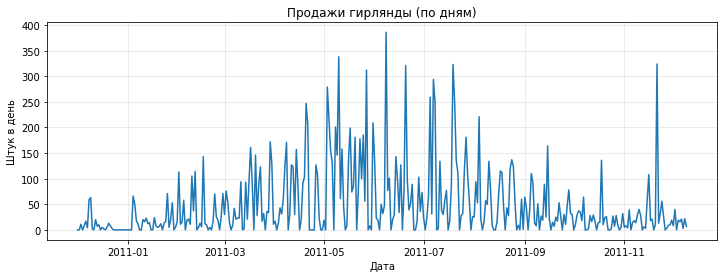

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily)
plt.title("Продажи гирлянды (по дням)")
plt.xlabel("Дата")
plt.ylabel("Штук в день")
plt.grid(alpha=0.3)
plt.show()

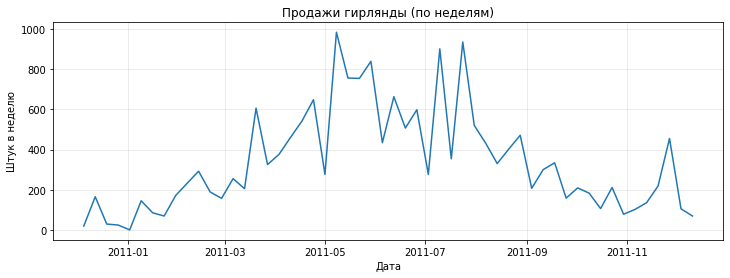

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(weekly.index, weekly)
plt.title("Продажи гирлянды (по неделям)")
plt.xlabel("Дата")
plt.ylabel("Штук в неделю")
plt.grid(alpha=0.3)
plt.show()

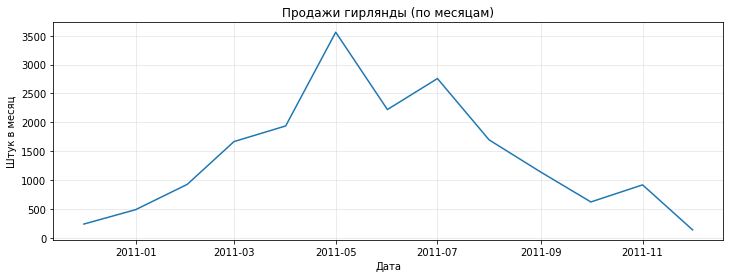

In [11]:
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly)
plt.title("Продажи гирлянды (по месяцам)")
plt.xlabel("Дата")
plt.ylabel("Штук в месяц")
plt.grid(alpha=0.3)
plt.show()

по графикам видно, что на дневном есть очень много скачков, которые сглаживаются в графиках по неделям и по месяцам. виден рост весной и снижение после лета. максимум месячных продаж приходится на май. для дальнейшего анализа оставлю дневной ряд, чтобы не потерять различия между днями недели.

#### 3. Пропуски и выбросы

In [ ]:
daily.isna().sum(), (daily == 0).sum()

(0, 80)

в дневных данных нет пропусков, однако есть 80 дней, когда продаж товара не было

In [15]:
store_rows = df.set_index("InvoiceDate").resample("D").size()

((daily == 0) & (store_rows != 0)).sum()

11

эти 80 дней делятся на две группы: 11 дней гирлянда не продавалась, но другие товары продавались, а остальные 69 дней продаж не было

найдем выбросы методом IQR

In [17]:
def find_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (s < lower) | (s > upper), upper

outliers, upper = find_outliers(daily)
upper, outliers.sum()

(158.625, 26)

всего этот метод выделил 26 выбросов. нанесем их на единый график вместе с нулевыми продажами

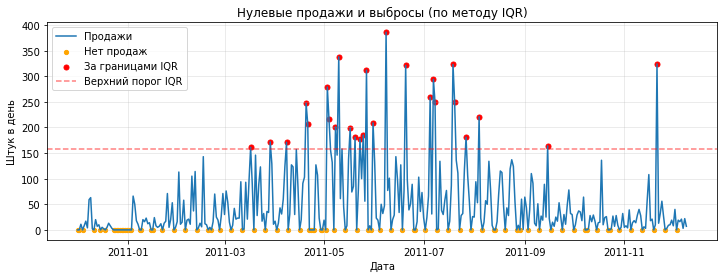

In [18]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily, label="Продажи")
plt.scatter(daily[daily == 0].index, daily[daily == 0], color="orange", s=18, label="Нет продаж")
plt.scatter(daily[outliers].index, daily[outliers], color="red", s=25, label="За границами IQR")
plt.axhline(upper, color="red", linestyle="--", alpha=0.5, label="Верхний порог IQR")
plt.title("Нулевые продажи и выбросы (по методу IQR)")
plt.xlabel("Дата")
plt.ylabel("Штук в день")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
outlier_info = product.resample("D").agg(
    total=("Quantity", "sum"),
    invoices=("InvoiceNo", "nunique"),
    max_quantity=("Quantity", "max"),
)

outlier_info.loc[daily[outliers].index].sort_values("total", ascending=False)

,total,invoices,max_quantity
2011-06-08,386,16,115.0
2011-05-10,338,18,150.0
2011-11-21,324,5,150.0
2011-07-19,323,12,88.0
2011-06-20,321,11,150.0
2011-05-27,312,8,143.0
2011-07-07,294,11,200.0
2011-05-03,279,13,124.0
2011-07-05,259,17,63.0
2011-07-20,250,7,150.0


по таблице видим, что часть объемов складывается из нескольких счетов, а часть связана с отдельнвми крупными записями (может быть, это оптовые продажи). большинство подобных дней приходится на более активный период май-июль, поэтому оснований считать данные значения ошибочными нет, оставим все без изменений

#### 4. Описательные статистики

In [28]:
def describe_sales(s):
    stats = s.describe()
    stats["cv"] = s.std() / s.mean()
    stats["skew"] = s.skew()
    stats["zero_share"] = (s == 0).mean()
    stats["missing"] = s.isna().sum()
    return stats

describe_sales(daily)

count         374.000000
mean           48.917112
std            67.320617
min             0.000000
25%             4.250000
50%            21.500000
75%            66.000000
max           386.000000
cv              1.376218
skew            2.191942
zero_share      0.213904
missing         0.000000
Name: Quantity, dtype: float64

основные описательные статистики:
* медиана - 21.5
* среднее - 48.92 (заметно выше медианы за счет крупных заказов)
* стандартное отклонение - 67.32
* коэффициент вариации - 1.38 (высокий разброс относительно среднего уровня)
* ассиметрия - 2.19 (длинный правый хвост, указывающий на отдельные крупные заказы)
* доля нулевых дней - 21.4%

построим график продаж и скользящего среднего (за 28 дней) и график стандартного отклонения (за 28 дней)

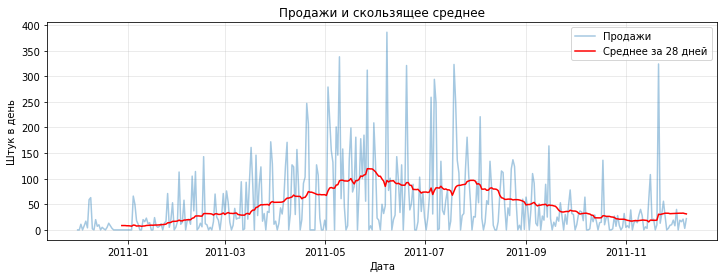

In [22]:
y = daily.iloc[:-1]
plt.figure(figsize=(12, 4))
plt.plot(y.index, y, alpha=0.4, label="Продажи")
plt.plot(y.index, y.rolling(28).mean(), color="red", label="Среднее за 28 дней")
plt.title("Продажи и скользящее среднее")
plt.xlabel("Дата")
plt.ylabel("Штук в день")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

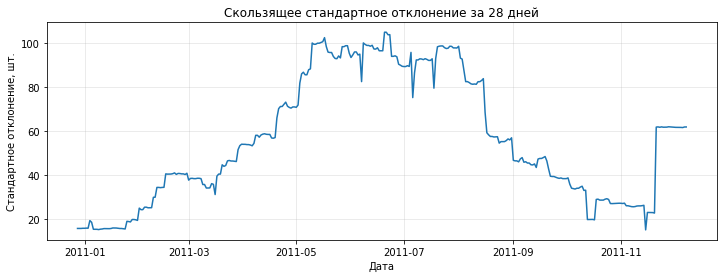

In [23]:
plt.figure(figsize=(12, 4))
plt.plot(y.index, y.rolling(28).std())
plt.title("Скользящее стандартное отклонение за 28 дней")
plt.xlabel("Дата")
plt.ylabel("Стандартное отклонение, шт.")
plt.grid(alpha=0.3)
plt.show()

скользящие среднее и стандартное отклонение растут весной, остаются высокими в начале лета и затем снижаются, то есть во времени меняются уровень продаж и их разброс. возможно, ряд нестационарен, далее это проверим

#### 5. Декомпозиция и сезонность

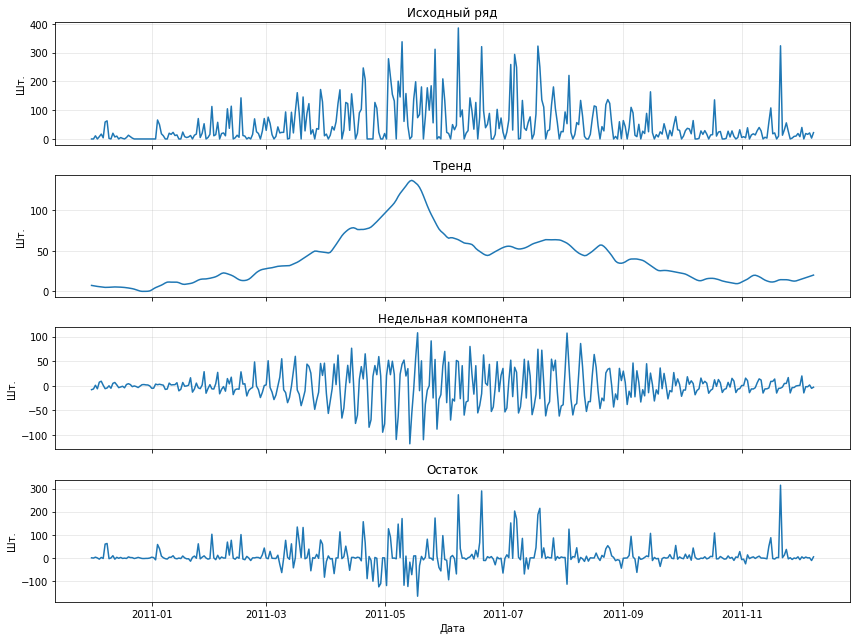

In [30]:
def plot_decomposition(s, period=7):
    result = STL(s, period=period, robust=True).fit()
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    values = [s, result.trend, result.seasonal, result.resid]
    titles = ['Исходный ряд', 'Тренд', 'Недельная компонента', 'Остаток']
    for ax, value, title in zip(axes, values, titles):
        ax.plot(s.index, value)
        ax.set_title(title)
        ax.set_ylabel('Шт.')
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel('Дата')
    plt.tight_layout()
    plt.show()
    return result

result = plot_decomposition(y, period=7)

для начала воспользуемся аддитивной моделью STL с периодом 7 дней с параметром robust = True для повышения устойчивости модели к выбросам. тренд отражает рост к весне и лету и последующее снижение, в сезонной компоненте виден недельный ритм, а в остатке присутствуют нерегулярные скачки.

проверим недельный ритм по дням недели, ACF и спектру.

начертим график средних продаж по дням недели

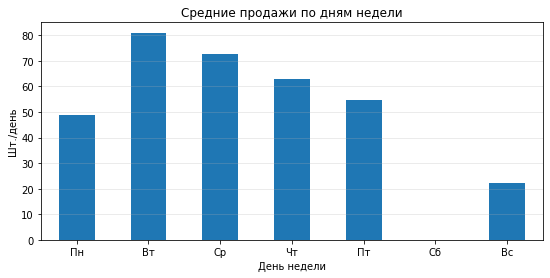

In [31]:
weekday_sales = y.groupby(y.index.dayofweek).mean()
weekday_sales.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_sales.plot(kind='bar', figsize=(9, 4))
plt.title('Средние продажи по дням недели')
plt.xlabel('День недели')
plt.ylabel('Шт./день')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

перед расчетом ACF вычтем из значений ряда тренд

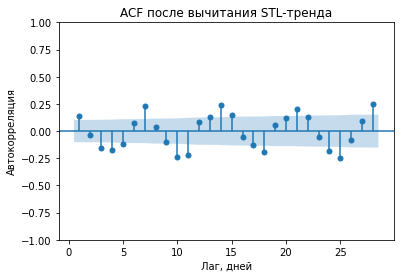

In [32]:
plot_acf(y - result.trend, lags=28, zero=False)
plt.title('ACF после вычитания STL-тренда')
plt.xlabel('Лаг, дней')
plt.ylabel('Автокорреляция')
plt.show()

оценим спектральную плотность мощности дневных продаж методом Уэлча

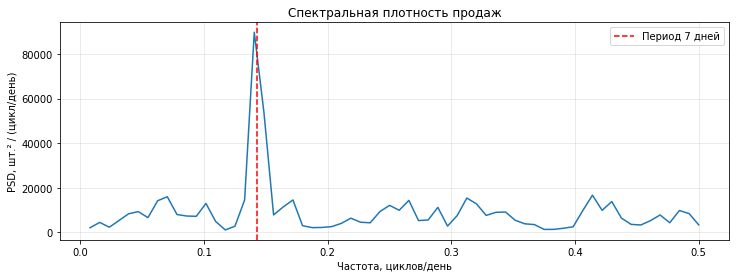

In [25]:
freqs, power = welch(y.to_numpy(), fs=1, nperseg=128, detrend='linear')
plt.figure(figsize=(12, 4))
plt.plot(freqs[1:], power[1:])
plt.axvline(1 / 7, color='red', linestyle='--', label='Период 7 дней')
plt.title('Спектральная плотность продаж')
plt.xlabel('Частота, циклов/день')
plt.ylabel('PSD, шт.² / (цикл/день)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

профиль дней недели, пики ACF на недельных лагах и спектральный пик около 1/7 подтверждают недельный ритм продаж. рост весной и спад осенью могут быть связаны со временем года, но годовую сезонность подтвердить нельзя из-за наличия данных только за один год.

#### 6. Проверка стационарности

для проверки стационарности воспользуемся тесатми ADF и KPSS при уровне значимости 0.05:

- тест ADF: нулевая гипотеза - единичный корень
- тест KPSS: нулевая гипотеза - стационарность около постоянного уровня

In [33]:
def check_stationarity(s):
    adf_result = adfuller(s, regression='c', autolag='AIC')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        kpss_result = kpss(s, regression='c', nlags='auto')
    p = kpss_result[1]
    kpss_p = '<0.01' if p == 0.01 else '>0.10' if p == 0.1 else round(p, 4)
    return pd.Series({
        'ADF statistic': adf_result[0],
        'ADF p-value': f'{adf_result[1]:.3g}',
        'KPSS statistic': kpss_result[0],
        'KPSS p-value': kpss_p,
    })

check_stationarity(y)

ADF statistic    -1.948197
ADF p-value           0.31
KPSS statistic    0.910564
KPSS p-value         <0.01
dtype: object

ADF дает p = 0.310, а KPSS показывает p < 0.01. противоречий между тестами нет, поскольку оба результата указывают на нестационарность исходного ряда около постоянного уровня. попробуем сделать преобразование продаж log1p, чтобы уменьшить влияние больших значений, и разность с лагом 7, чтобы сравнивать одинаковые дни недели.

In [39]:
log_sales = np.log1p(y)
transformed = log_sales.diff(7).dropna()

значения тестов для логарифмированного ряда и для логарифмированного ряда разностей

In [40]:
check_stationarity(log_sales)

ADF statistic    -2.318041
ADF p-value          0.166
KPSS statistic    1.098642
KPSS p-value         <0.01
dtype: object

In [41]:
check_stationarity(transformed)

ADF statistic    -6.776945
ADF p-value       2.56e-09
KPSS statistic    0.057362
KPSS p-value         >0.10
dtype: object

построим графики этих преобразований

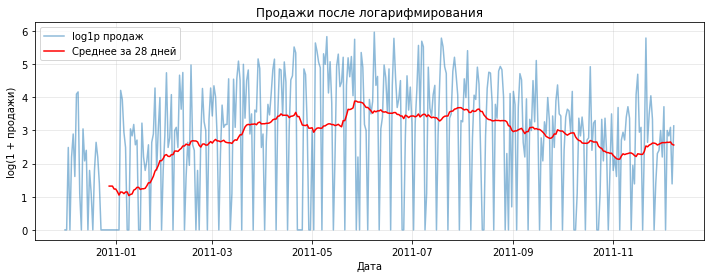

In [44]:
log_sales = np.log1p(y)
plt.figure(figsize=(12, 4))
plt.plot(log_sales.index, log_sales, alpha=0.5,
         label="log1p продаж")
plt.plot(log_sales.index, log_sales.rolling(28).mean(),
         color="red", label="Среднее за 28 дней")
plt.title("Продажи после логарифмирования")
plt.xlabel("Дата")
plt.ylabel("log(1 + продажи)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

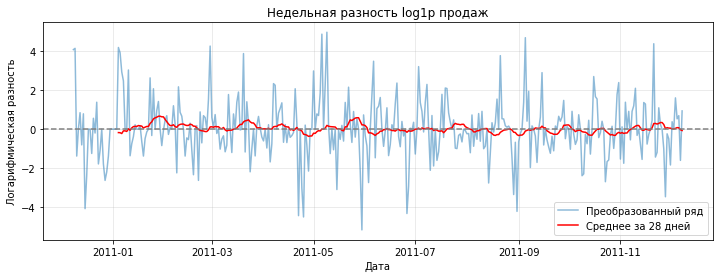

In [45]:
plt.figure(figsize=(12, 4))
plt.plot(transformed.index, transformed, alpha=0.5, label="Преобразованный ряд")
plt.plot(
    transformed.index,
    transformed.rolling(28).mean(),
    color="red",
    label="Среднее за 28 дней",
)
plt.axhline(0, color="grey", linestyle="--")
plt.title("Недельная разность log1p продаж")
plt.xlabel("Дата")
plt.ylabel("Логарифмическая разность")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

по результатам тестов и по графикам можем заметить, что логарифмирования данных недостаточно, ряд все еще нестационарен. однако после недельной разности на логарифмированных данных ADF показывает p $\approx$ 2.56e-09, KPSS p > 0.10, то есть гипотеза о стационарности ряда не отвергается.

#### Выводы

* для анализа выбран товар 47566 (гирлянда). для данных построены дневной, недельный и месячный ряды. после исключения возвратов и бесплатных выдач осталось 1706 записей и 18295 проданных гирлянд, пропусков в полях нет. в данных выявлено 80 дней без зарегистрированных продаж товара

* поиск выбросов метод IQR отметил 26 потенциальных выбросов, однако после аналитики мы их не убрали из ряда, поскольку крупные объемы могут соответствовать оптовым заказам, а явных оснований считать их ошибками не найдено.

* анализ описательных статистик (медианы, среднего, коэффициента вариации) указывает на большой разброс в продажах гирлянд. отдельные крупные заказы формируют правый хвост распределения. скользящие среднее и стандартное отклонение (за 28 дней) показывают, что уровень и разброс продаж меняются во времени.

* разложение ряда на тренд, сезонность и остатки, профиль дней недели, ACF и спектральная плотность указывают на недельный ритм продаж. рост весной и снижение после лета наблюдаются, но годовую сезонность подтвердить нельзя из-за короткой истории.

* исходный ряд нестационарен по обоим тестам (ADF, KPSS), поэтому были выполнены преобразования продаж: логарифмирование (его оказалось недостаточно) и логарифмирование + разность с лагом 7 дней (здесь результаты тестов не отвергают гипотезу стационарности).  преобразования уменьшают влияние крупных значений и изменения уровня между неделями.

* в целом, ряд может быть использован для прогнозирования, поскольку в нем присутствуют закономерности, полезные для краткосрочного прогнозирования, однако крупные редкие заказы и неопределенность нулевых значений вносят свои проблемы